In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/powerlifting.db")

q_anio = """
SELECT Year,
       ROUND(AVG(CASE WHEN MeetCountry = 'Argentina' THEN Dots END), 1) AS dots_arg,
       ROUND(AVG(CASE WHEN MeetCountry <> 'Argentina' THEN Dots END), 1) AS dots_mundo
FROM powerlifting
WHERE Equipment = 'Raw' AND Sex IN ('M', 'F') AND Year >= 2021
GROUP BY Year
ORDER BY Year
"""

q_sexo = """
SELECT CASE WHEN MeetCountry = 'Argentina' THEN 'Argentina' ELSE 'Resto del mundo' END AS grupo,
       Sex,
       ROUND(AVG(Dots), 1) AS dots_promedio
FROM powerlifting
WHERE Equipment = 'Raw' AND Sex IN ('M', 'F') AND Year >= 2023
GROUP BY grupo, Sex
"""

anio = pd.read_sql_query(q_anio, conn)
sexo = pd.read_sql_query(q_sexo, conn)
piv = (sexo.pivot(index="Sex", columns="grupo", values="dots_promedio")
           .rename(index={"M": "Hombres", "F": "Mujeres"})
           .loc[["Hombres", "Mujeres"]])

In [2]:
display(anio)
display(piv)

,Year,dots_arg,dots_mundo
0,2021,324.8,346.9
1,2022,330.1,348.1
2,2023,326.1,351.3
3,2024,353.9,351.8
4,2025,364.8,353.5
5,2026,364.8,342.5


grupo,Argentina,Resto del mundo
Sex,,
Hombres,358.9,362.1
Mujeres,337.7,327.3


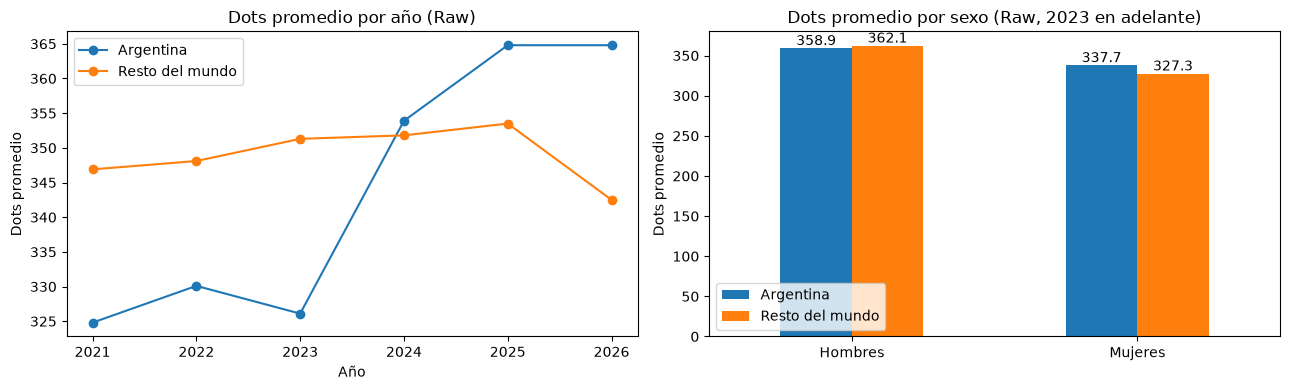

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(anio["Year"], anio["dots_arg"], marker="o", label="Argentina")
ax[0].plot(anio["Year"], anio["dots_mundo"], marker="o", label="Resto del mundo")
ax[0].set_xticks(anio["Year"])
ax[0].set_title("Dots promedio por año (Raw)")
ax[0].set_xlabel("Año"); ax[0].set_ylabel("Dots promedio"); ax[0].legend()

piv.plot(kind="bar", ax=ax[1], rot=0)
for c in ax[1].containers:
    ax[1].bar_label(c)
ax[1].set_title("Dots promedio por sexo (Raw, 2023 en adelante)")
ax[1].set_xlabel(""); ax[1].set_ylabel("Dots promedio"); ax[1].legend(title="")

plt.tight_layout()
plt.savefig("../images/argentina.png", dpi=150)
plt.show()